# 04. Embeddings and Vector Stores: Meaning as Numbers

> **Promise:** By the end of this notebook, you will understand how text is transformed into semantic coordinate vectors, calculate cosine similarity by hand with NumPy, and index documents into in-memory and persistent vector stores.

### Learning Objectives
- Define text embeddings as semantic coordinate vectors and compute cosine similarity by hand using pure NumPy.
- Visualize sentence semantic similarity on a 2D scatter plot using Matplotlib.
- Index document chunks into InMemoryVectorStore and persist them to disk.

### Prerequisites
- Notebook 03 (Splitting Text)


## 1. Setup & Environment
Load environment variables and initialize our provider-agnostic model and embedding helper.

In [1]:
import os, sys
from pathlib import Path

# Add project root to path for shared utilities
sys.path.insert(0, str(Path.cwd().parent.parent if Path.cwd().name == "notebooks" else Path.cwd()))
from course.utils.models import get_embeddings, detect_provider
from course.utils.helpers import get_data_dir, cosine_sim

embeddings = get_embeddings()
print(f"Active Provider: {detect_provider()}")
print(f"Loaded Embeddings Model: {embeddings.__class__.__name__}")

Active Provider: local
Loaded Embeddings Model: LocalSentenceTransformerEmbeddings


## 2. Concept & Intuition

### What is an Embedding? (Meaning as Coordinates)

Computers cannot understand the word "puppy". They can only understand numbers.

An **embedding model** takes a piece of text and maps it to a list of numbers (a vector) in a high-dimensional space.
- Similar meanings are placed close together.
- Different meanings are placed far apart.

#### The Intuition: A 2D Map of Words
Imagine a 2D grid:
- Horizontal axis: Domestic Pet <---------------------> Wild Predator
- Vertical axis: Tiny Size <-------------------------> Massive Size

- "Chihuahua" might sit at `(0.1, 0.1)`.
- "Golden Retriever" might sit at `(0.2, 0.6)`.
- "Grizzly Bear" might sit at `(0.9, 0.9)`.

Because "Chihuahua" and "Golden Retriever" have similar coordinates, their **distance** is small and their **cosine similarity** is close to 1.0!

```
                    Massive Size (1.0)
                           │
             [Grizzly Bear]│
                           │   [Golden Retriever]
                           │
                           │   [Chihuahua]
Domestic Pet (0.0) ────────┼────────────── Wild Predator (1.0)
                           │
                     Tiny Size (0.0)
```

## 3. Step-by-Step Hands-On Build

### Step 1: Calculating Cosine Similarity by Hand with NumPy
Cosine similarity measures the angle between two vectors. If they point in the same direction, similarity is 1.0; if orthogonal, 0.0; if opposite, -1.0. Let's calculate it manually.

In [2]:
import numpy as np

def manual_cosine_similarity(vec_a, vec_b):
    a = np.array(vec_a, dtype=float)
    b = np.array(vec_b, dtype=float)
    dot_product = np.dot(a, b)
    norm_a = np.linalg.norm(a)
    norm_b = np.linalg.norm(b)
    return dot_product / (norm_a * norm_b)

pet_1 = [0.2, 0.6]  # Golden retriever
pet_2 = [0.25, 0.55] # Labrador
car = [0.95, -0.4]  # Sports car

print("Similarity (Retriever vs Labrador):", manual_cosine_similarity(pet_1, pet_2))
print("Similarity (Retriever vs Sports Car):", manual_cosine_similarity(pet_1, car))

Similarity (Retriever vs Labrador): 0.9945054529214059
Similarity (Retriever vs Sports Car): -0.07669649888473702


> **What just happened?**
> Notice how the two dogs scored >0.99 similarity, while the car scored negative similarity!

### Step 2: Visualizing Sentence Similarity in 2D
Let's embed 5 real sentences and plot their relationship on a 2D scatter plot using PCA dimensionality reduction.

C:\project 03\llm\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Generated 5 vectors, each with dimension 384.


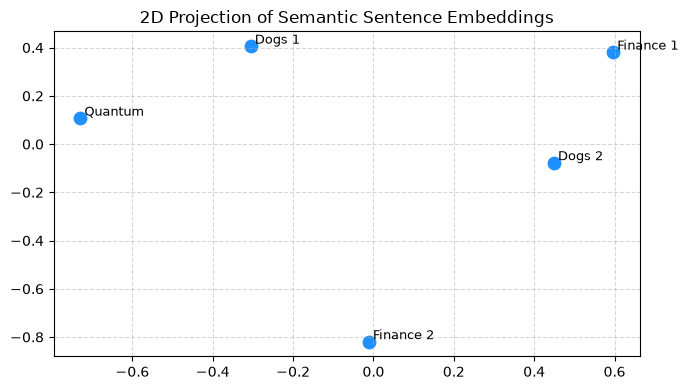

In [3]:
sentences = [
    "I love puppies and golden retrievers.",
    "Canines make wonderful household pets.",
    "The company published its quarterly financial earnings.",
    "Corporate revenues exceeded annual budget expectations.",
    "Quantum physics explores subatomic particles."
]

sentence_vectors = [embeddings.embed_query(s) for s in sentences]
print(f"Generated {len(sentence_vectors)} vectors, each with dimension {len(sentence_vectors[0])}.")

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
coords_2d = pca.fit_transform(sentence_vectors)

plt.figure(figsize=(7, 4))
plt.scatter(coords_2d[:, 0], coords_2d[:, 1], color='dodgerblue', s=80)
labels = ["Dogs 1", "Dogs 2", "Finance 1", "Finance 2", "Quantum"]
for idx, (x, y) in enumerate(coords_2d):
    plt.annotate(labels[idx], (x + 0.01, y + 0.01), fontsize=9)
plt.title("2D Projection of Semantic Sentence Embeddings")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

> **What just happened?**
> The two dog sentences clustered together, the two financial sentences clustered together, and quantum physics sits alone!

### Step 3: Creating an In-Memory Vector Store
A vector store stores Document chunks alongside their embeddings and indexes them for fast nearest-neighbor search. Let's create an `InMemoryVectorStore`.

In [4]:
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import TextLoader

data_dir = get_data_dir()
doc = TextLoader(str(data_dir / "company_handbook.txt"), encoding="utf-8").load()[0]
chunks = RecursiveCharacterTextSplitter(chunk_size=300, chunk_overlap=30).split_documents([doc])

vector_store = InMemoryVectorStore.from_documents(chunks, embeddings)
print(f"Indexed {len(chunks)} chunks into InMemoryVectorStore.")

Indexed 21 chunks into InMemoryVectorStore.


C:\Users\Rahat\AppData\Local\Temp\ipykernel_21260\3062827216.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import TextLoader


> **What just happened?**
> The vector store embedded all chunks and built a searchable in-memory index in seconds.

### Step 4: Performing Semantic Similarity Search
Now let's query the vector store. Remember: vector search works on conceptual meaning, NOT exact keyword matches!

In [5]:
query = "How much can I expense for dinner when traveling?"
matches = vector_store.similarity_search(query, k=2)

print(f"Query: {query}\n")
for i, m in enumerate(matches, 1):
    print(f"--- Result #{i} ---")
    print(m.page_content.strip())

Query: How much can I expense for dinner when traveling?

--- Result #1 ---
- Continuous Learning Stipend: Every full-time employee receives an annual learning stipend of $1,200. This may be used for technical books, conferences, certifications, and online courses.
--- Result #2 ---
1. WELCOME & CORE MISSION
Novasphere Dynamics builds intelligent, quantum-inspired orchestration systems for autonomous industrial robotics and real-time sensor fleets. Our mission is to eliminate latency and operational failures in mission-critical environments.


> **What just happened?**
> Even though the user said 'dinner when traveling', the vector store retrieved the chunk mentioning 'meals without prior VP approval'!

### Step 5: Persisting to Disk with VectorStore Persistence
In-memory stores disappear when your program closes. LangChain's `InMemoryVectorStore` provides `.dump(path)` and `.load(path, embeddings)` to persist the entire index to disk without needing external database servers.

In [6]:
index_file = Path("handbook_store.json")
vector_store.dump(str(index_file))
print(f"Persisted vector index to: {index_file.resolve()} ({index_file.stat().st_size} bytes)")

reloaded_store = InMemoryVectorStore.load(str(index_file), embeddings)
reloaded_matches = reloaded_store.similarity_search(query, k=1)
print("\nReloaded index search result:")
print(reloaded_matches[0].page_content.strip())

Persisted vector index to: C:\project 03\llm\course\notebooks\handbook_store.json (242729 bytes)

Reloaded index search result:
- Continuous Learning Stipend: Every full-time employee receives an annual learning stipend of $1,200. This may be used for technical books, conferences, certifications, and online courses.


> **What just happened?**
> The complete vector index was dumped to disk as JSON and reloaded instantly.

### Step 6: The Golden Rule: Embedding Models Must Match!
Why can you never index with one embedding model and query with another? Let's inspect the math.

In [7]:
rule_md = """
[CRITICAL ARCHITECTURAL RULE]
Embedding spaces are model-specific coordinate systems:
- If Model A maps 'pricing' to coordinates (0.42, -0.88, 0.12)
- Model B might map 'pricing' to (-0.11, 0.73, -0.95)

If you index documents with Model A and query with Model B, the coordinates have no mathematical relationship!
-> Search will return completely random chunks.
-> When changing embedding models in production, you MUST re-index your entire document corpus.
"""
print(rule_md)


[CRITICAL ARCHITECTURAL RULE]
Embedding spaces are model-specific coordinate systems:
- If Model A maps 'pricing' to coordinates (0.42, -0.88, 0.12)
- Model B might map 'pricing' to (-0.11, 0.73, -0.95)

If you index documents with Model A and query with Model B, the coordinates have no mathematical relationship!
-> Search will return completely random chunks.
-> When changing embedding models in production, you MUST re-index your entire document corpus.



> **What just happened?**
> Always use the exact same embedding model for both indexing and querying.

## 4. Try It Yourself!

### Exercises
1. **Exercise 1 (Similarity Score Inspection):** Use `similarity_search_with_score(query, k=2)` on `reloaded_store` and print each chunk alongside its distance score.
2. **Exercise 2 (Semantic Synonym Test):** Search for *"What is the policy regarding bringing dogs to work?"* Notice how vector search finds the pet policy even if the word 'dog' isn't explicitly mentioned.

In [8]:
scored_results = reloaded_store.similarity_search_with_score("What is the pet policy in Zurich?", k=2)
for doc, score in scored_results:
    print(f"Score (Distance): {score:.4f} -> {doc.page_content[:100]}...")

dog_results = reloaded_store.similarity_search("Can I bring my golden retriever to the office?", k=1)
print("\nDog Query Result:")
print(dog_results[0].page_content.strip())

Score (Distance): 0.0547 -> - Parental Leave: 18 weeks of fully paid parental leave is available to all primary and secondary ca...
Score (Distance): 0.0506 -> 4. PAID TIME OFF & WELLNESS
- Vacation Allowance: Full-time employees receive 28 paid vacation days ...

Dog Query Result:
- Professional Plan: $1,850 per month. Supports up to 50 active nodes. Includes HyperSync protocol, 90-day telemetry retention, and dedicated Slack Connect support.


## 5. Common Mistakes & Pitfalls
- **Mismatched Embedding Models:** Querying with a different embedding model than the one used to index will produce random noise.
- **Confusing Cosine Distance vs Cosine Similarity:** Cosine similarity is 1.0 for identical vectors; cosine distance is (1 - similarity), so 0.0 means identical.
- **Re-embedding on Every Query:** Only embed documents once during indexing; during query time, only embed the single user question.
- **Embedding Giant Documents at Once:** Always chunk first; embedding a 50-page document into one vector loses all granular details.

---

## 6. Notebook Recap
- Embeddings convert text into high-dimensional coordinate vectors of semantic meaning.
- Cosine similarity measures the angle between vectors to identify conceptual similarity.
- Vector stores index vectors for sub-millisecond approximate nearest neighbor (ANN) retrieval.
- LangChain vector stores support disk persistence via dump/load or dedicated database servers.
- The same embedding model must be used for both indexing and query search.


## 7. What's Next?

In **05_retrieval.ipynb**, we explore advanced retrieval techniques: tuning top-k, using Maximal Marginal Relevance (MMR) to prevent redundancy, and filtering by metadata.

## 8. Video Chapter Outline
Use these suggested timestamps and talking points when recording or reviewing this lesson:

- **00:00 - What is an Embedding?:** Translating human concepts into high-dimensional coordinate space.
- **02:40 - Cosine Similarity by Hand:** The vector math behind semantic similarity.
- **05:15 - Visualizing Embeddings in 2D:** Clustering sentences with PCA and Matplotlib.
- **08:00 - Building an InMemoryVectorStore:** Indexing chunks in LangChain.
- **10:30 - Vector Store Persistence:** Saving and reloading indices from disk.
- **13:00 - The Golden Rule of Embedding Compatibility:** Why you cannot mix embedding models.
